# AIE464 Final Project: Text-Preserving Image Denoising

**Bangkok University | AIE464** | GPU: Google Colab Tesla T4 | โค้ดที่ใช้เทรนและประเมินผล: commit `75664d9`

Notebook นี้คือไฟล์ที่ใช้เทรนและประเมินผลจริงทั้งหมด output ของ cell 1–10 เป็นผลจากการรันจริงบน Colab T4 (ไม่ได้แก้ไข) ส่วนหัวข้อ **"ผลลัพธ์และการเปรียบเทียบ"** ท้ายไฟล์สร้างตาราง กราฟ และภาพเปรียบเทียบจากผลเหล่านั้น

> **วิธีรัน:** ห้ามกด Run all เพราะ cell 6 คือการเทรน 16 jobs (หลายชั่วโมง) ถ้าต้องการดูผลใหม่ ให้รันเฉพาะหัวข้อผลลัพธ์ (cell 11 เป็นต้นไป) ซึ่งตั้งค่าตัวเองได้โดยไม่ต้องรัน cell ก่อนหน้า

### ผลสรุปย่อ (รายละเอียดในหัวข้อ 7–8)

| คำถาม | ผล |
|---|---|
| Augmentation ช่วยไหม | In-domain ไม่ต่างอย่างมีนัยสำคัญ (32.15 vs 31.84 dB, p=0.375) แต่ทนต่อ domain shift ดีขึ้นชัด (Augraphy 17.48 vs 14.53 dB, p<0.001) |
| Knowledge Distillation (W10) | CNN 7k params ดีขึ้น 28.84 vs 27.71 dB (p<0.001) ขนาดและความเร็วเท่าเดิม |
| Fine-tune ข้าม dataset (W9) | DIBCO FM 61.9 → 84.4 (p<0.001) |
| LoRA (W12) | FM 84.4 เท่า full fine-tune โดยเทรนแค่ราว 13% ของ params |
| Pretrained NAFNet (W9) | ดีที่สุดบน DIBCO (FM 88.0) แต่บน Kaggle ไม่ดีกว่า U-Net ทั้งที่ใหญ่กว่า 60 เท่าและช้ากว่า 16 เท่า |
| ข้อแลกเปลี่ยน | Fine-tune บน DIBCO ทำให้ผลบน Kaggle ตกเหลือ 20–23 dB (catastrophic forgetting) |

---

## 1. เป้าหมาย

- ปรับปรุงโมเดล denoise เอกสารจาก midterm ด้วยเทคนิคหลัง midterm (W9, W10, W12) และเทียบกับโมเดลเดิมแบบ **same circumstance** คือใช้ test set ชุดเดียวกัน วิธีวัดผลเดียวกัน และ GPU เดียวกัน
- ทดสอบความทนทานเมื่อข้อมูลเปลี่ยน 2 แบบ:
  1. **Augraphy shift:** ภาพ test ของ Kaggle ที่ใส่ความเสียหายแบบใหม่ที่โมเดลไม่เคยเห็น
  2. **DIBCO 2017:** dataset อื่น เป็นเอกสารเก่าจริงทั้งแบบพิมพ์และลายมือ
- ขนาด input เท่ากับ output เสมอ ($H \times W \rightarrow H \times W$) ไม่ใช่งาน super-resolution

## 2. ข้อมูลและที่มา

| ชุด | ที่มา | ใช้ทำอะไร | จำนวน | วิธีวัด |
|---|---|---|---|---|
| Kaggle Denoising Dirty Documents | [kaggle.com/c/denoising-dirty-documents](https://www.kaggle.com/c/denoising-dirty-documents) | train / val / **test (in-domain)** | test 24 ภาพจาก 6 หน้าต้นฉบับ แบ่งระดับหน้าเพื่อกัน data leakage | PSNR, SSIM, text PSNR |
| Augraphy shift | สร้างจาก Kaggle test ด้วยไลบรารี [Augraphy](https://github.com/sparkfish/augraphy) แบบ deterministic | test เท่านั้น | 24 ภาพ | เหมือน Kaggle |
| DIBCO 2017 | [Document Image Binarization Contest 2017](https://vc.ee.duth.gr/dibco2017/) | **test (cross-dataset)** เท่านั้น | 20 ภาพ (printed 10, handwritten 10) | binarize ด้วย Otsu แล้ววัด FM, pFM, PSNR, DRD |
| DIBCO 2018 + 2019A | การแข่งขัน DIBCO ปีถัดมา (H-DIBCO 2018, DIBCO 2019 track A) | fine-tune เท่านั้น (ไม่ใช้ปี 2017 เพื่อกัน data leakage) | 20 หน้า แบ่ง train 16 / val 4 (seed 42) | val PSNR |

- **Data leakage:** แบ่ง train/val/test ระดับหน้าเอกสารก่อนตัด patch ภาพจากหน้าเดียวกันจึงไม่อยู่คนละชุด
- **text PSNR:** PSNR เฉพาะบริเวณตัวอักษร
- **FM (F-measure):** พิกเซลหมึกที่ทำนายตรงกับ GT แค่ไหน ยิ่งสูงยิ่งดี
- **pFM:** F-measure ที่ดูโครงเส้นตัวอักษร (skeleton)
- **DRD:** ความผิดเพี้ยนที่สายตามนุษย์สังเกตได้ **ยิ่งต่ำยิ่งดี**
- **การวัดบน DIBCO:** GT ของ DIBCO เป็นภาพขาวดำ ทุกโมเดลจึงถูก binarize ด้วย Otsu ก่อนวัดผล แถว "Otsu on raw input" คือการ binarize ภาพดิบโดยไม่ผ่านโมเดล ใช้เป็น baseline ว่าโมเดลช่วยได้จริงหรือไม่

ไฟล์ข้อมูลทั้งหมดรวมไว้ใน `MyDrive/AIE464_runs/data/aie464_data.zip`

## 3. Edge-aware loss (Sobel)

Sobel คือ kernel ขนาด 3×3 ที่หาความเปลี่ยนแปลงของความสว่างในแนวนอน (Gx) และแนวตั้ง (Gy) ขอบตัวอักษรจะมีค่าสูง ใน loss เราเทียบ edge map ของภาพที่โมเดลทำนายกับของ GT เพื่อบังคับให้โมเดลรักษาขอบตัวอักษรไว้:

$$\text{loss} = L_1(\hat{y}, y) + \lambda \cdot L_1(\text{Sobel}(\hat{y}), \text{Sobel}(y))$$

ค่า λ ที่ทดลองคือ 0, 0.1 (ค่าหลัก) และ 0.5

## 4. โมเดล

- **Baseline จาก midterm:** ShallowCNN, DnCNN, U-Net (L1), U-Net + edge loss ใช้ checkpoint เดิมโดยไม่เทรนใหม่
- **SmallUNet:** encoder 3 ชั้น (max pool), decoder ใช้ nearest upsampling + skip connection, ทำนาย noise แล้วลบออกจาก input (residual) ขนาด 487,009 params
- **NAFNet-SIDD-width32:** pretrained model ภายนอก (29.2M params)

## 5. เทคนิคหลัง midterm ที่ใช้

| สัปดาห์ | เทคนิค | Job |
|---|---|---|
| W9 | Transfer learning / fine-tune ข้าม dataset (Kaggle → DIBCO 2018+2019A, test บน DIBCO 2017): full FT และ freeze encoder | `ft_full`, `ft_freeze_enc`, `nafnet_ft_dibco_full` |
| W9 | Pretrained model ภายนอก: NAFNet (เทรนบน SIDD) ทดสอบ zero-shot แล้ว fine-tune บน Kaggle | `nafnet_zeroshot`, `nafnet_ft` |
| W10 | Knowledge Distillation: teacher `unet_edge_aug` → student ShallowCNN (7k params) | `kd_cnn` |
| W12 | Parameter-efficient fine-tune: LoRA บน conv (rank 4 / 8) | `ft_lora4`, `ft_lora8`, `nafnet_ft_dibco_lora8` |
| ทุก job | Augmentation (photometric, blur, JPEG, noise), cosine LR, AMP, gradient clipping | `*_aug` |

**Budget (ตั้งหลังรัน pilot):** UNet / DnCNN / KD 30 epochs × 2,000 samples, Fine-tune DIBCO 20 × 1,000, `nafnet_ft` 20 × 1,000, NAFNet → DIBCO 10 × 1,000 ทุก job ใช้ seed 42 ยกเว้น `unet_edge_aug_s43` และ `unet_edge_aug_s44`

---

## 6. กระบวนการเทรนและประเมินผล (cell 1–10, output จากการรันจริง)

โค้ดของ dataset, model, loss และ training loop อยู่ในโฟลเดอร์ `mini_project/src/` ของ repo notebook นี้ clone repo ตาม commit ที่ระบุ เพื่อให้ทุก session ของ Colab ใช้โค้ดชุดเดียวกันเป๊ะ


### Cell 1: ตั้งค่า
รวมค่าทั้งหมดไว้ที่เดียว `GIT_SHA` ล็อก commit ของโค้ด, `BUDGETS` คือจำนวน epoch × samples ของแต่ละ job, `MAX_MINUTES` ให้หยุดพักอย่างปลอดภัยก่อน Colab ตัด session

In [1]:
# 1. Config: every setting lives here
DRIVE_ROOT = '/content/drive/MyDrive/AIE464_runs'
REPO_URL = 'https://github.com/chayanon25/aie464-text-preserving-denoising.git'
GIT_SHA = '75664d90511597a54575137a096c8b154eceb1bc'         # set to the exact commit sha before running jobs
JOB_ID = None             # None = claim the next pending job from runs/jobs.json
OWNER = 'account-1'       # a label for this Colab account
SMOKE = False            # True = tiny synthetic CPU run, no Drive
MAX_MINUTES = 330         # pause safely before Colab kills the session (rerun to resume)
LOCAL_REPO = None

# Training budget per job: (epochs, samples_per_epoch). Filled in after the pilot
# (plan Task 12); only jobs listed here are registered. Pilot budgets use equal
# optimizer steps: 2000/8 (U-Net) == 1000/4 (NAFNet) == 250 steps.
# Approved after the Task 12 pilot (UNet 16.7 s / 2000 samples, NAFNet 101 s / 1000 samples on T4).
# Order matters: claim_next takes jobs top-down and does not check dependencies,
# so parents (unet_edge_aug, nafnet_ft) come before the jobs that load them.
BUDGETS = {
    'pilot_unet_edge_aug': (1, 2000),
    'nafnet_short_ft': (1, 1000),
    'unet_edge_aug': (30, 2000),
    'nafnet_ft': (20, 1000),
    'dncnn_nobn_aug': (30, 2000),
    'unet_aug_l0': (30, 2000),
    'unet_aug_l05': (30, 2000),
    'unet_edge_aug_s43': (30, 2000),
    'unet_edge_aug_s44': (30, 2000),
    'kd_cnn': (30, 2000),
    'ft_full': (20, 1000),
    'ft_freeze_enc': (20, 1000),
    'ft_lora4': (20, 1000),
    'ft_lora8': (20, 1000),
    'nafnet_ft_dibco_full': (10, 1000),
    'nafnet_ft_dibco_lora8': (10, 1000),
}

# "Run on any folder" (cell 9): leave INPUT_DIR = None to skip.
INPUT_DIR = None
GT_DIR = None
OUTPUT_DIR = None
MODEL_REF = 'unet_edge_aug'   # job_id, 'midterm:<exp>' or 'nafnet:sidd'


### Cell 2: เตรียมโค้ด
mount Google Drive (ที่เก็บข้อมูล checkpoint และผล) แล้ว clone โค้ดตาม `GIT_SHA` output ยืนยัน commit ที่ใช้จริง

In [2]:
# 2. Mount Drive, clone the repo at GIT_SHA, put mini_project/ on sys.path
import os, subprocess, sys
from pathlib import Path
if SMOKE:
    MINI = Path(LOCAL_REPO)
    RUNS_ROOT = Path('runs').resolve()
else:
    from google.colab import drive
    drive.mount('/content/drive')
    if not Path('/content/repo').exists():
        subprocess.run(['git', 'clone', '-q', REPO_URL, '/content/repo'], check=True)
    subprocess.run(['git', '-C', '/content/repo', 'fetch', '-q', 'origin'], check=True)
    subprocess.run(['git', '-C', '/content/repo', 'checkout', '-q', GIT_SHA], check=True)
    MINI = Path('/content/repo/mini_project')
    RUNS_ROOT = Path(DRIVE_ROOT) / 'runs'
RUNS_ROOT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(MINI))
SHA = subprocess.run(['git', '-C', str(MINI), 'rev-parse', 'HEAD'], capture_output=True, text=True).stdout.strip() or None
print('code sha:', SHA, '| runs:', RUNS_ROOT)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
code sha: 75664d90511597a54575137a096c8b154eceb1bc | runs: /content/drive/MyDrive/AIE464_runs/runs


### Cell 3: ติดตั้งไลบรารีเสริม
`augraphy` ใช้สร้างความเสียหายเทียม และ `scikit-image` ใช้คำนวณ SSIM

In [3]:
# 3. Extra packages (Colab already ships torch; never reinstall it)
if not SMOKE:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'augraphy', 'scikit-image'], check=True)


### Cell 4: ข้อมูลและ unit test
แตก zip ข้อมูลจาก Drive รัน unit test ชุดเร็วเพื่อยืนยันว่าโค้ดทำงานถูกก่อนเทรน (output: test ผ่านทั้งหมด) และกำหนดฟังก์ชันโหลด train/val/test

In [4]:
# 4. Data: unzip the Drive bundle, run the fast test suite, define data loaders
import torch
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
if SMOKE:
    from src.smoke import smoke_data
    SMOKE_SETS = smoke_data()
else:
    DATA_ROOT = Path('/content/data')
    if not (DATA_ROOT / 'raw').exists():
        subprocess.run(['unzip', '-q', '-o', f'{DRIVE_ROOT}/data/aie464_data.zip', '-d', str(DATA_ROOT)], check=True)
    os.environ['MIDTERM_CKPT_DIR'] = str(DATA_ROOT / 'checkpoints')
    os.environ['NAFNET_WEIGHTS'] = str(DATA_ROOT / 'nafnet' / 'NAFNet-SIDD-width32.pth')
    for sub in ('raw', 'external'):
        link = MINI / 'data' / sub
        link.parent.mkdir(exist_ok=True)
        if not link.exists():
            link.symlink_to(DATA_ROOT / sub)
    _t = subprocess.run([sys.executable, '-m', 'pytest', '-q', '-x', '-m', 'not slow'], cwd=MINI, capture_output=True, text=True)
    print(_t.stdout[-4000:], _t.stderr[-2000:])
    assert _t.returncode == 0, 'fast test suite failed (see output above)'

def get_job_data(cfg):
    if SMOKE:
        return SMOKE_SETS[cfg.data]
    if cfg.data == 'kaggle':
        from src.dataset import load_kaggle_split
        manifest = MINI / 'outputs' / 'phase1' / 'split_manifest.json'
        return {s: load_kaggle_split(DATA_ROOT / 'raw', manifest, s) for s in ('train', 'val')}
    from src.data_external import dibco_finetune_split
    return dibco_finetune_split(DATA_ROOT / 'external' / 'dibco', seed=42)

def get_testsets():
    if SMOKE:
        return SMOKE_SETS['testsets']
    from src.eval_suite import load_testsets
    return load_testsets(DATA_ROOT / 'raw', MINI / 'outputs' / 'phase1' / 'split_manifest.json',
                         DATA_ROOT / 'external' / 'augraphy_shift', DATA_ROOT / 'external' / 'dibco',
                         required=('kaggle_test', 'augraphy_shift', 'dibco2017'))
print('device:', DEVICE)


........................................................................ [ 77%]
..ssss......s........                                                    [100%]
88 passed, 5 skipped, 5 deselected in 61.92s (0:01:01)
 
device: cuda


### Cell 5: ลงทะเบียน jobs
ทุก job ถูกบันทึกใน `runs/jobs.json` บน Drive พร้อมสถานะ (pending / running / done) เพื่อให้รันต่อได้เมื่อ Colab หลุด output นี้คือสถานะตอนรันรอบสุดท้าย

In [5]:
# 5. Register budgeted jobs in the shared registry (idempotent)
from src.experiments import JOBS, with_budget
from src.jobs import JobRegistry
REGISTRY = JobRegistry(RUNS_ROOT / 'jobs.json')
SMOKE_OVERRIDES = dict(batch_size=2, patch=64, amp=False)

def budgeted(job_id):
    if SMOKE:
        return with_budget(job_id, 1, 4, git_sha=SHA, **SMOKE_OVERRIDES)
    epochs, samples = BUDGETS[job_id]
    return with_budget(job_id, epochs, samples, git_sha=SHA)

for job_id in (['pilot_unet_edge_aug'] if SMOKE else BUDGETS):
    REGISTRY.add(budgeted(job_id))
print(REGISTRY.summary())


{'pilot_unet_edge_aug': 'done', 'nafnet_short_ft': 'done', 'unet_edge_aug': 'running', 'nafnet_ft': 'pending', 'dncnn_nobn_aug': 'pending', 'unet_aug_l0': 'pending', 'unet_aug_l05': 'pending', 'unet_edge_aug_s43': 'pending', 'unet_edge_aug_s44': 'pending', 'kd_cnn': 'pending', 'ft_full': 'pending', 'ft_freeze_enc': 'pending', 'ft_lora4': 'pending', 'ft_lora8': 'pending', 'nafnet_ft_dibco_full': 'pending', 'nafnet_ft_dibco_lora8': 'pending'}


### Cell 6: เทรน
เทรนทุก job ที่ค้างอยู่ต่อกัน บันทึก checkpoint ทุก epoch และหยุดพักก่อนหมดเวลา ถ้า Colab หลุดก็รันใหม่แล้วทำต่อจาก epoch ล่าสุด

output ด้านล่างเป็น log ของ session สุดท้าย (การเทรนทั้งหมดกระจายหลาย session) log ครบทุก epoch ของทั้ง 16 jobs อยู่ใน `runs/<job>/validation.json` และวาดเป็นกราฟในหัวข้อผลลัพธ์

In [6]:
# 6. Run jobs back to back: JOB_ID set = that job only, None = every pending job in BUDGETS order.
# Checkpoint + heartbeat every epoch; pauses before MAX_MINUTES. If Colab drops, rerun cells 1-6 to resume.
import time
from src.train_engine import run_job
started = time.time()
while True:
    if JOB_ID:
        cfg = budgeted(JOB_ID)
        REGISTRY.add(cfg)
        if REGISTRY.status(JOB_ID) == 'done':
            print(JOB_ID, 'already done'); break
        REGISTRY.mark(JOB_ID, 'running', owner=OWNER)
    else:
        cfg = REGISTRY.claim_next(OWNER)
    if cfg is None:
        print('No pending job: all done.'); break
    data, result = get_job_data(cfg), None
    while (left := MAX_MINUTES - (time.time() - started) / 60) > 0:
        result = run_job(cfg, RUNS_ROOT / cfg.job_id, data, DEVICE, max_minutes=left, max_epochs=1,
                         runs_root=RUNS_ROOT, on_progress=lambda: REGISTRY.heartbeat(cfg.job_id, owner=OWNER))
        REGISTRY.heartbeat(cfg.job_id, owner=OWNER)
        last = result['history'][-1] if result['history'] else {}
        print(cfg.job_id, result['status'], last)
        if result['status'] == 'done':
            REGISTRY.mark(cfg.job_id, 'done', owner=OWNER)
            break
    if JOB_ID or not (result and result['status'] == 'done'):
        print('stopped at', cfg.job_id, 'status:', result and result['status'],
              '(time budget reached: rerun cells 1-6 to continue)' if left <= 0 else ''); break
print(REGISTRY.summary())


unet_edge_aug paused {'epoch': 2, 'train_loss': 0.047868744894862175, 'val_psnr': 29.436715507507323, 'lr': 0.0009891830623632318, 'seconds': 16.988641023635864, 'peak_vram_mb': 394.41845703125}
unet_edge_aug paused {'epoch': 3, 'train_loss': 0.04257707396894694, 'val_psnr': 30.087033176422118, 'lr': 0.0009757729755660888, 'seconds': 14.341429233551025, 'peak_vram_mb': 394.41845703125}
unet_edge_aug paused {'epoch': 4, 'train_loss': 0.03698030649870634, 'val_psnr': 28.6598858833313, 'lr': 0.0009572050015330757, 'seconds': 15.17894172668457, 'peak_vram_mb': 394.41845703125}
unet_edge_aug paused {'epoch': 5, 'train_loss': 0.03187673062831163, 'val_psnr': 30.211850738525392, 'lr': 0.0009336825748732853, 'seconds': 14.49092960357666, 'peak_vram_mb': 394.41845703125}
unet_edge_aug paused {'epoch': 6, 'train_loss': 0.030209266304969788, 'val_psnr': 29.916061401367188, 'lr': 0.0009054634122155883, 'seconds': 14.463958024978638, 'peak_vram_mb': 394.41845703125}
unet_edge_aug paused {'epoch': 7

### Cell 7: ประเมินผล
วัดทุกโมเดลบน test set ทั้ง 3 ชุดด้วย test set และวิธีวัดเดียวกัน (same circumstance) รวมโมเดล midterm, NAFNet zero-shot และวิธี classical บันทึกผลรายภาพไว้ใน `runs/eval/*.json`

In [7]:
# 7. Evaluate every finished run (plus midterm and classical baselines) on all test sets
import json
from src.classical import CLASSICAL
from src.eval_suite import evaluate, predict_fn, save_eval
from src.train_engine import load_trained
TESTSETS = get_testsets()
EVAL_TILE = 1024
models = {}
for job_id, status in REGISTRY.summary().items():
    if status == 'done' and (RUNS_ROOT / job_id / 'best.pt').exists():
        models[job_id] = job_id
if not SMOKE:
    for exp in ('cnn_l1', 'dncnn_lite', 'unet_l1', 'unet_edge'):
        models[f'midterm_{exp}'] = f'midterm:{exp}'
    if Path(os.environ['NAFNET_WEIGHTS']).exists():
        models['nafnet_zeroshot'] = 'nafnet:sidd'
for name, ref in models.items():
    out = RUNS_ROOT / 'eval' / f'{name}.json'
    if out.exists():
        continue
    model = load_trained(ref, RUNS_ROOT, DEVICE)
    save_eval(evaluate(predict_fn(model, DEVICE, tile=EVAL_TILE, amp=False), TESTSETS, name), out)
    print('evaluated', name)
for name, fn in CLASSICAL.items():
    out = RUNS_ROOT / 'eval' / f'classical_{name}.json'
    if not out.exists():
        save_eval(evaluate(fn, TESTSETS, f'classical_{name}'), out)


evaluated pilot_unet_edge_aug
evaluated nafnet_short_ft
evaluated unet_edge_aug
evaluated nafnet_ft
evaluated dncnn_nobn_aug
evaluated unet_aug_l0
evaluated unet_aug_l05
evaluated unet_edge_aug_s43
evaluated unet_edge_aug_s44
evaluated kd_cnn
evaluated ft_full
evaluated ft_freeze_enc
evaluated ft_lora4
evaluated ft_lora8
evaluated nafnet_ft_dibco_full
evaluated nafnet_ft_dibco_lora8
evaluated midterm_cnn_l1
evaluated midterm_dncnn_lite
evaluated midterm_unet_l1
evaluated midterm_unet_edge
evaluated nafnet_zeroshot


### Cell 8: ความเร็ว
วัด latency บนภาพ 540×420, warm-up 10 รอบ วัดจริง 50 รอบ ใช้ค่า median พร้อม peak VRAM และจำนวน params

In [8]:
# 8. Latency: warm-up 10, measure 50, median ms + peak VRAM + params (540x420 page)
from src.infer import measure_latency
latency_path = RUNS_ROOT / 'latency.json'
latency = json.loads(latency_path.read_text()) if latency_path.exists() else {}
for name, ref in models.items():
    if name not in latency:
        model = load_trained(ref, RUNS_ROOT, DEVICE)
        latency[name] = measure_latency(model, (1, 1, 540, 420), DEVICE,
                                        warmup=2 if SMOKE else 10, iters=3 if SMOKE else 50)
        latency[name]['device'] = torch.cuda.get_device_name() if DEVICE == 'cuda' else 'cpu'
latency_path.write_text(json.dumps(latency, indent=2))
print(json.dumps(latency, indent=2))


{
  "pilot_unet_edge_aug": {
    "median_ms": 8.50340749911993,
    "p90_ms": 10.838066000360413,
    "peak_vram_mb": 106.716796875,
    "params": 487009,
    "device": "Tesla T4"
  },
  "nafnet_short_ft": {
    "median_ms": 133.02548000046954,
    "p90_ms": 135.0885701001971,
    "peak_vram_mb": 374.7978515625,
    "params": 29159715,
    "device": "Tesla T4"
  },
  "unet_edge_aug": {
    "median_ms": 8.800196000265714,
    "p90_ms": 9.039621399097086,
    "peak_vram_mb": 106.716796875,
    "params": 487009,
    "device": "Tesla T4"
  },
  "nafnet_ft": {
    "median_ms": 140.55979699969612,
    "p90_ms": 142.9561842995099,
    "peak_vram_mb": 374.7978515625,
    "params": 29159715,
    "device": "Tesla T4"
  },
  "dncnn_nobn_aug": {
    "median_ms": 12.049735000800865,
    "p90_ms": 12.257191999378847,
    "peak_vram_mb": 56.5166015625,
    "params": 46849,
    "device": "Tesla T4"
  },
  "unet_aug_l0": {
    "median_ms": 9.258523999960744,
    "p90_ms": 9.509356501075672,
    "peak_v

### Cell 9: ใช้กับโฟลเดอร์ภาพอื่น
ตั้ง `INPUT_DIR` ใน cell 1 เพื่อ denoise ทุกภาพในโฟลเดอร์ ถ้าตั้ง `GT_DIR` ด้วยจะคำนวณ metric ให้ (ไม่ได้ใช้ในรอบนี้ จึงไม่มี output)

In [ ]:
# 9. Run on any folder: denoise every image, save PNGs, score against GT if given
from src.infer import run_folder
if INPUT_DIR:
    model = load_trained(MODEL_REF, RUNS_ROOT, DEVICE)
    rows = run_folder(model, INPUT_DIR, OUTPUT_DIR or f'{INPUT_DIR}_denoised', DEVICE, gt_dir=GT_DIR, tile=EVAL_TILE)
    for row in rows:
        print(row)


### Cell 10: สรุปผล PSNR
รวมผลของทุกโมเดลไว้ใน `runs/summary.json` output แสดง PSNR บน test ทั้ง 3 ชุด

In [9]:
# 10. Export a compact summary for the report (copy runs/ to outputs/final/runs/ locally)
summary = {}
for path in sorted((RUNS_ROOT / 'eval').glob('*.json')):
    summary[path.stem] = json.loads(path.read_text())['summary']
(RUNS_ROOT / 'summary.json').write_text(json.dumps({'git_sha': SHA, 'summary': summary,
                                                    'latency': latency}, indent=2))
for name, s in summary.items():
    print(name, {k: round(v.get('psnr', float('nan')), 2) for k, v in s.items() if '/' not in k})


classical_median3 {'kaggle_test': 14.29, 'augraphy_shift': 9.58, 'dibco2017': 14.03}
classical_noisy {'kaggle_test': 16.3, 'augraphy_shift': 9.93, 'dibco2017': 13.96}
classical_otsu {'kaggle_test': 15.21, 'augraphy_shift': 4.23, 'dibco2017': 13.96}
classical_sauvola {'kaggle_test': 15.53, 'augraphy_shift': 14.55, 'dibco2017': 14.73}
dncnn_nobn_aug {'kaggle_test': 31.94, 'augraphy_shift': 16.72, 'dibco2017': 11.8}
ft_freeze_enc {'kaggle_test': 21.53, 'augraphy_shift': 16.87, 'dibco2017': 15.23}
ft_full {'kaggle_test': 22.51, 'augraphy_shift': 16.66, 'dibco2017': 15.71}
ft_lora4 {'kaggle_test': 21.2, 'augraphy_shift': 16.55, 'dibco2017': 15.46}
ft_lora8 {'kaggle_test': 20.03, 'augraphy_shift': 16.26, 'dibco2017': 15.54}
kd_cnn {'kaggle_test': 28.84, 'augraphy_shift': 16.55, 'dibco2017': 12.14}
midterm_cnn_l1 {'kaggle_test': 27.71, 'augraphy_shift': 15.3, 'dibco2017': 13.68}
midterm_dncnn_lite {'kaggle_test': 31.67, 'augraphy_shift': 14.85, 'dibco2017': 12.3}
midterm_unet_edge {'kaggle_te

---

## 7. ผลลัพธ์และการเปรียบเทียบ

ส่วนนี้รันแยกได้ใน session ใหม่ (ไม่ต้องรัน cell 1–10) โดยอ่านผลประเมินรายภาพและ latency ที่ cell 7–8 บันทึกไว้ แล้วสร้างตาราง กราฟ และภาพเปรียบเทียบ โค้ดสร้างตารางอยู่ใน `src/report.py` และโค้ดสร้างรูปอยู่ใน `tools/make_figures.py`

> **ที่มาของ output ในหัวข้อนี้:** รันบนเครื่องของผู้จัดทำ โดยใช้ไฟล์ที่ดาวน์โหลดจาก Drive หลังรัน cell 1–10 บน Colab (`best.pt`, `validation.json`, `eval/*.json`, `latency.json`) ตัวเลขในตารางคำนวณจากผลประเมินของ Colab โดยตรง ส่วนภาพเปรียบเทียบ denoise ใหม่ด้วย checkpoint เดียวกันบน CPU บน Colab cell 11 จะอ่านไฟล์ชุดเดียวกันจาก Drive แทน

> **หมายเหตุ midterm:** `midterm_unet_edge` ได้ 31.84 dB ตรงกับ checkpoint และผล benchmark ของ midterm ที่เก็บไว้ ส่วนค่า 31.865 dB ที่เคยรายงานตอน midterm มาจากอีกรันหนึ่งที่ไม่มี checkpoint เหลืออยู่ จึงรายงานไว้ทั้งสองค่า

In [11]:
# 11. Report setup: runs on its own in a fresh session (do NOT rerun cells 1-10)
# On Colab: read the runs from Drive. Elsewhere: use the same files downloaded into mini_project/outputs/final/.
import os, subprocess, sys, json
from pathlib import Path
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if IN_COLAB:
    drive.mount('/content/drive')
    DRIVE_ROOT = '/content/drive/MyDrive/AIE464_runs'
    REPO_URL = 'https://github.com/chayanon25/aie464-text-preserving-denoising.git'
    RUNS = Path(DRIVE_ROOT) / 'runs'
    EVAL_DIR, LATENCY_PATH = RUNS / 'eval', RUNS / 'latency.json'
    REPO = Path('/content/report_repo')
    if not REPO.exists():
        subprocess.run(['git', 'clone', '-q', REPO_URL, str(REPO)], check=True)
    MINI = REPO / 'mini_project'
    FIG_DIR = Path('/content/figures')
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'augraphy', 'scikit-image'], check=True)
    DATA_ROOT = Path('/content/data')
    if not (DATA_ROOT / 'raw').exists():
        subprocess.run(['unzip', '-q', '-o', f'{DRIVE_ROOT}/data/aie464_data.zip', '-d', str(DATA_ROOT)], check=True)
    os.environ['MIDTERM_CKPT_DIR'] = str(DATA_ROOT / 'checkpoints')
    for sub in ('raw', 'external'):
        link = MINI / 'data' / sub
        link.parent.mkdir(exist_ok=True)
        if not link.exists():
            link.symlink_to(DATA_ROOT / sub)
else:
    MINI = Path.cwd().resolve().parent  # this notebook lives in mini_project/notebooks/
    RUNS = MINI / 'outputs' / 'final' / 'runs'
    EVAL_DIR = MINI / 'results' / 'final_benchmark'
    LATENCY_PATH = MINI / 'results' / 'final_benchmark' / 'latency.json'
    FIG_DIR = MINI / 'outputs' / 'final' / 'notebook_figures'
sys.path.insert(0, str(MINI))
sha = subprocess.run(['git', '-C', str(MINI), 'rev-parse', '--short', 'HEAD'], capture_output=True, text=True).stdout.strip()
print('environment:', 'Colab' if IN_COLAB else 'local copy of the Colab runs', '| report code:', sha)
print('eval files:', len(list(EVAL_DIR.glob('*.json'))), '| trained runs:', len(list(RUNS.glob('*/best.pt'))))

environment: local copy of the Colab runs | report code: be321ee
eval files: 27 | trained runs: 27


### 7.1 ตารางผล
ทุกตารางคำนวณจากผลรายภาพใน `runs/eval/*.json` ค่า p มาจาก paired Wilcoxon signed-rank test (two-sided) ซึ่งทดสอบว่าความต่างรายภาพระหว่าง 2 โมเดลมีนัยสำคัญหรือไม่

In [12]:
# 12. Result tables
from IPython.display import Markdown, display
from src.report import build_tables
TITLES = {'in_domain': 'In-domain (Kaggle test, 24 ภาพ)', 'augraphy_shift': 'Domain shift (Augraphy, 24 ภาพ)',
          'dibco2017': 'Cross-dataset (DIBCO 2017, 20 ภาพ)', 'finetune': 'Fine-tune และการลืมงานเดิม (forgetting)',
          'efficiency': 'Efficiency (540x420, batch 1, Tesla T4, median 50 รอบ)',
          'wilcoxon': 'ทดสอบนัยสำคัญ (paired Wilcoxon)'}
tables = build_tables(EVAL_DIR, latency_path=LATENCY_PATH)
for key, table in tables.items():
    display(Markdown(f'#### {TITLES.get(key, key)}\n\n{table}'))

#### In-domain (Kaggle test, 24 ภาพ)

| model | PSNR (dB) | SSIM | text PSNR (dB) |
|---|---|---|---|
| midterm_cnn_l1 | 27.71 | 0.981 | 21.59 |
| kd_cnn | 28.84 | 0.982 | 23.42 |
| midterm_dncnn_lite | 31.67 | 0.992 | 25.53 |
| dncnn_nobn_aug | 31.94 | 0.991 | 26.32 |
| midterm_unet_l1 | 31.51 | 0.986 | 25.40 |
| midterm_unet_edge | 31.84 | 0.989 | 25.44 |
| unet_edge_aug | 31.19 | 0.990 | 25.95 |
| unet_edge_aug_s43 | 31.37 | 0.990 | 25.56 |
| unet_edge_aug_s44 | 31.64 | 0.992 | 26.06 |
| unet_aug_l0 | 31.48 | 0.991 | 26.10 |
| unet_aug_l05 | 32.15 | 0.992 | 26.37 |
| nafnet_zeroshot | 14.97 | 0.781 | 12.24 |
| nafnet_ft | 31.19 | 0.990 | 25.20 |
| noisy input | 16.30 | 0.849 | 20.70 |
| classical_median3 | 14.29 | 0.704 | 9.91 |
| classical_sauvola | 15.53 | 0.866 | 11.10 |
| classical_otsu | 15.21 | 0.867 | 11.10 |

#### Domain shift (Augraphy, 24 ภาพ)

| model | PSNR (dB) | SSIM | text PSNR (dB) |
|---|---|---|---|
| midterm_cnn_l1 | 15.30 | 0.728 | 6.95 |
| kd_cnn | 16.55 | 0.800 | 9.05 |
| midterm_dncnn_lite | 14.85 | 0.711 | 6.46 |
| dncnn_nobn_aug | 16.72 | 0.810 | 9.35 |
| midterm_unet_l1 | 14.84 | 0.718 | 6.33 |
| midterm_unet_edge | 14.53 | 0.698 | 5.93 |
| unet_edge_aug | 17.48 | 0.850 | 10.89 |
| unet_edge_aug_s43 | 17.41 | 0.848 | 10.70 |
| unet_edge_aug_s44 | 17.41 | 0.846 | 10.70 |
| unet_aug_l0 | 17.54 | 0.850 | 10.96 |
| unet_aug_l05 | 17.16 | 0.840 | 10.30 |
| nafnet_zeroshot | 9.67 | 0.537 | 7.83 |
| nafnet_ft | 17.16 | 0.845 | 10.73 |
| noisy input | 9.93 | 0.614 | 9.09 |
| classical_median3 | 9.58 | 0.494 | 7.09 |
| classical_sauvola | 14.55 | 0.772 | 8.08 |
| classical_otsu | 4.23 | 0.403 | 8.71 |

#### Cross-dataset (DIBCO 2017, 20 ภาพ)

| model | FM all | FM printed | FM handwritten | pFM | PSNR | DRD (lower better) |
|---|---|---|---|---|---|---|
| Otsu on raw input | 78.04 | 83.93 | 72.16 | 80.52 | 13.96 | 14.90 |
| classical_sauvola | 77.64 | 79.55 | 75.73 | 87.16 | 14.73 | 7.28 |
| midterm_unet_edge | 62.37 | 70.87 | 53.86 | 72.29 | 13.32 | 10.21 |
| unet_edge_aug | 61.91 | 63.59 | 60.22 | 74.19 | 12.80 | 12.23 |
| nafnet_zeroshot | 76.50 | 82.45 | 70.56 | 78.54 | 13.46 | 16.42 |
| nafnet_ft | 66.53 | 70.06 | 63.00 | 75.55 | 13.02 | 11.77 |
| ft_full | 84.36 | 82.47 | 86.25 | 87.30 | 15.71 | 6.64 |
| ft_freeze_enc | 77.53 | 82.66 | 72.40 | 82.96 | 15.23 | 6.94 |
| ft_lora4 | 82.86 | 80.78 | 84.93 | 86.02 | 15.46 | 7.11 |
| ft_lora8 | 84.38 | 82.56 | 86.21 | 86.70 | 15.54 | 6.86 |
| nafnet_ft_dibco_full | 87.98 | 88.09 | 87.86 | 90.71 | 16.89 | 5.05 |
| nafnet_ft_dibco_lora8 | 85.28 | 86.59 | 83.98 | 90.24 | 16.04 | 5.70 |

#### Fine-tune และการลืมงานเดิม (forgetting)

| model | DIBCO FM | DIBCO DRD | Kaggle PSNR (forgetting) |
|---|---|---|---|
| unet_edge_aug | 61.91 | 12.23 | 31.19 |
| ft_full | 84.36 | 6.64 | 22.51 |
| ft_freeze_enc | 77.53 | 6.94 | 21.53 |
| ft_lora4 | 82.86 | 7.11 | 21.20 |
| ft_lora8 | 84.38 | 6.86 | 20.03 |
| nafnet_ft | 66.53 | 11.77 | 31.19 |
| nafnet_ft_dibco_full | 87.98 | 5.05 | 21.43 |
| nafnet_ft_dibco_lora8 | 85.28 | 5.70 | 22.98 |

#### Efficiency (540x420, batch 1, Tesla T4, median 50 รอบ)

| model | params | median ms (540x420, T4) | peak VRAM MB |
|---|---|---|---|
| unet_edge_aug | 487,009 | 8.8 | 107 |
| nafnet_ft | 29,159,715 | 140.6 | 375 |
| dncnn_nobn_aug | 46,849 | 12.0 | 57 |
| unet_aug_l0 | 487,009 | 9.3 | 107 |
| unet_aug_l05 | 487,009 | 9.3 | 107 |
| unet_edge_aug_s43 | 487,009 | 9.2 | 107 |
| unet_edge_aug_s44 | 487,009 | 9.4 | 107 |
| kd_cnn | 7,265 | 4.0 | 31 |
| ft_full | 487,009 | 9.6 | 107 |
| ft_freeze_enc | 487,009 | 9.5 | 107 |
| ft_lora4 | 518,661 | 17.6 | 133 |
| ft_lora8 | 550,313 | 18.1 | 133 |
| nafnet_ft_dibco_full | 29,159,715 | 154.6 | 375 |
| nafnet_ft_dibco_lora8 | 30,131,731 | 212.5 | 491 |
| midterm_cnn_l1 | 7,265 | 3.8 | 31 |
| midterm_dncnn_lite | 47,009 | 11.9 | 57 |
| midterm_unet_l1 | 487,009 | 8.6 | 107 |
| midterm_unet_edge | 487,009 | 8.9 | 107 |
| nafnet_zeroshot | 29,159,715 | 136.1 | 375 |

#### ทดสอบนัยสำคัญ (paired Wilcoxon)

| A | B | test set | metric | n | median(A-B) | p (two-sided) |
|---|---|---|---|---|---|---|
| unet_edge_aug | midterm_unet_edge | kaggle_test | psnr | 24 | -0.39 | 0.121 |
| unet_aug_l05 | midterm_unet_edge | kaggle_test | psnr | 24 | 0.46 | 0.375 |
| dncnn_nobn_aug | midterm_dncnn_lite | kaggle_test | psnr | 24 | -0.02 | 0.406 |
| kd_cnn | midterm_cnn_l1 | kaggle_test | psnr | 24 | 1.15 | <0.001 |
| nafnet_ft | unet_edge_aug | kaggle_test | psnr | 24 | 0.18 | 1.000 |
| unet_edge_aug | midterm_unet_edge | augraphy_shift | psnr | 24 | 2.74 | <0.001 |
| ft_full | unet_edge_aug | dibco2017 | fm | 20 | 17.06 | <0.001 |
| ft_lora8 | ft_full | dibco2017 | fm | 20 | 0.16 | 1.000 |
| nafnet_ft_dibco_full | ft_full | dibco2017 | fm | 20 | 3.80 | 0.006 |

### 7.2 ภาพประกอบและภาพเปรียบเทียบ
สร้างใหม่จาก checkpoint `best.pt` ของแต่ละ job บน Drive และ log การเทรน `validation.json` (seed 42)

figures: 10


**ตัวอย่างข้อมูล: Kaggle, Augraphy shift และ DIBCO 2017**

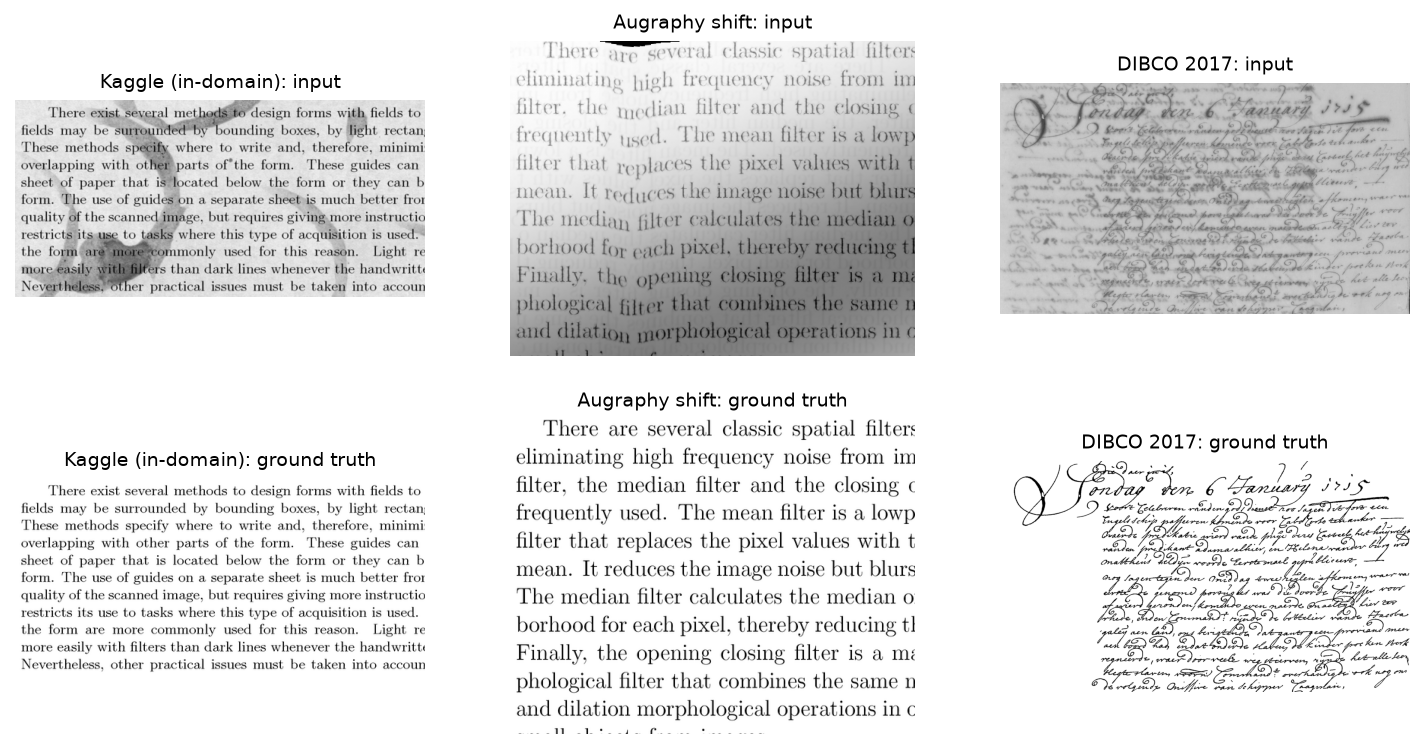

**Sobel: kernel Gx/Gy และ edge map ที่ใช้ใน edge loss**

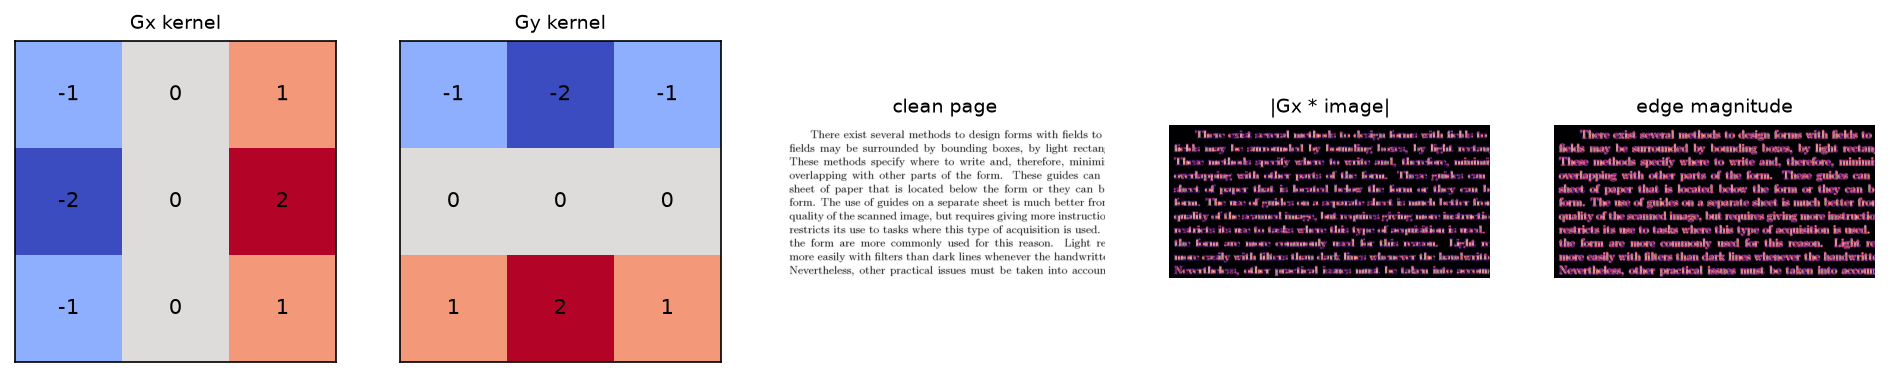

**SmallUNet: shape ทุกชั้นจากการรันจริงบนภาพ 256x256**

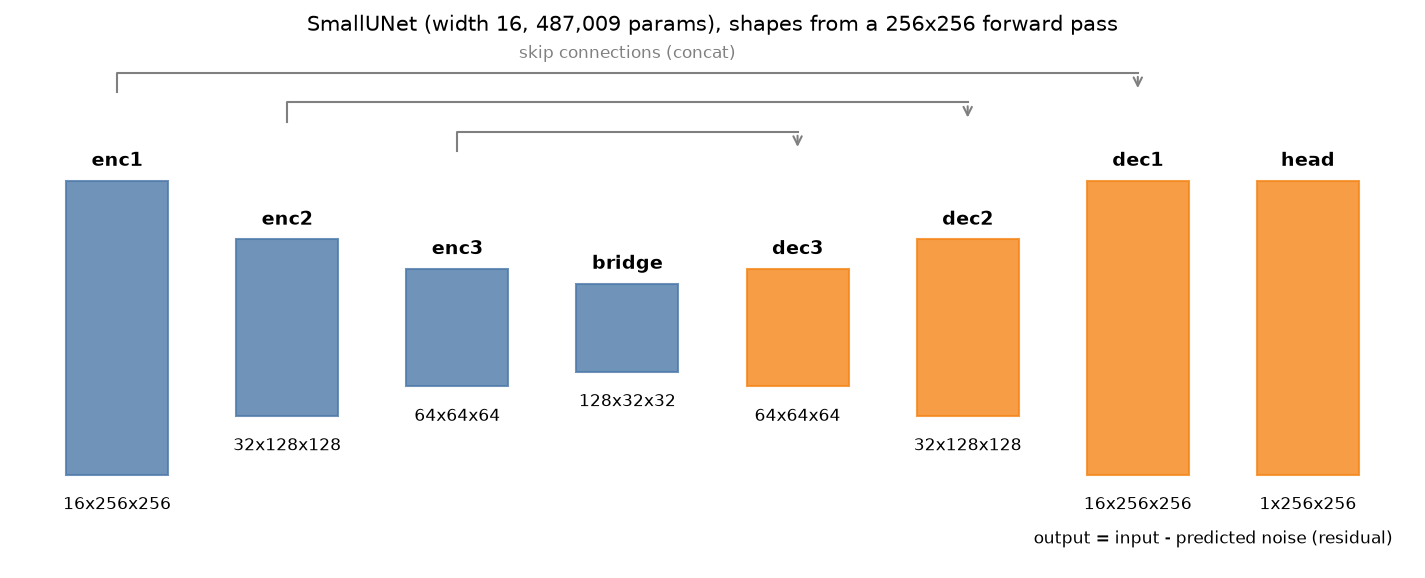

**Validation PSNR ระหว่างเทรน: ซ้าย Kaggle, ขวา fine-tune บน DIBCO**

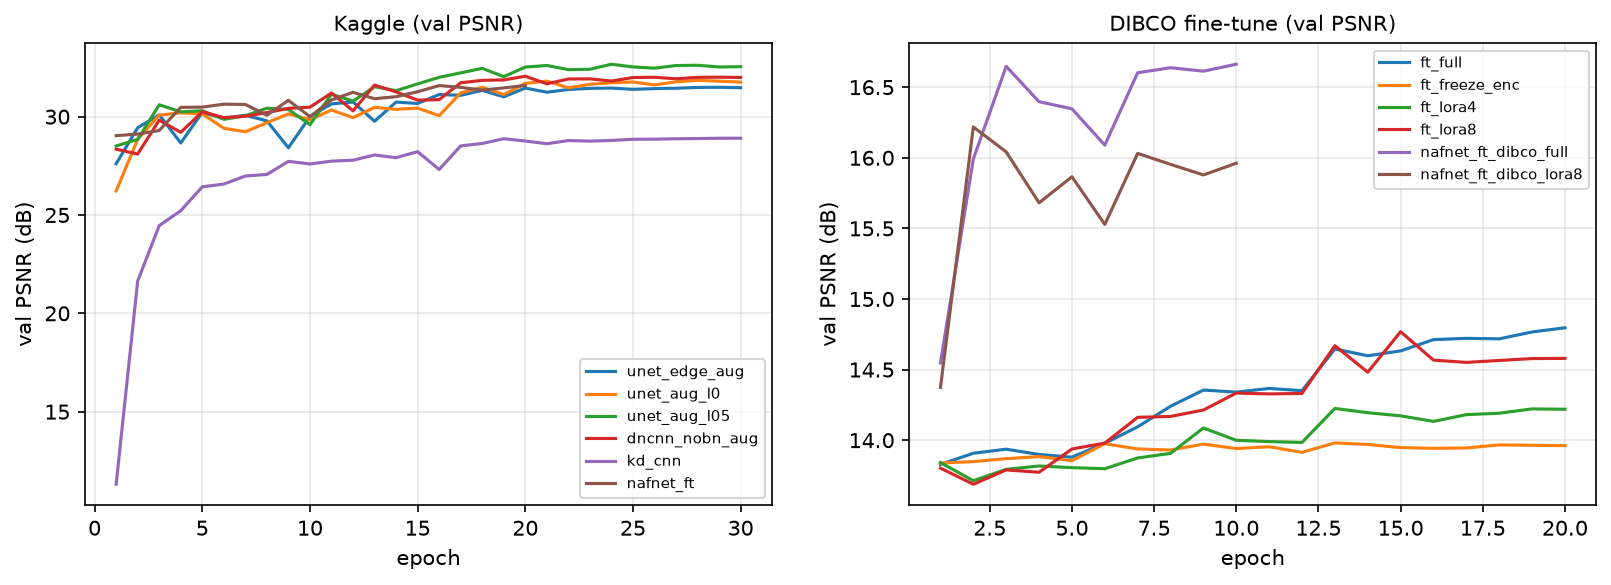

**Kaggle test: ทุกโมเดลลบคราบได้ใกล้เคียงกัน nafnet_ft ให้ตัวอักษรหนากว่า GT**

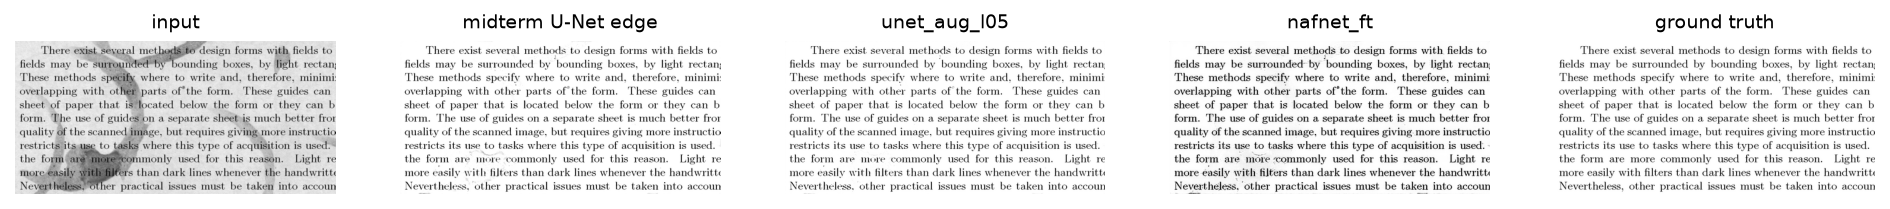

**Kaggle test (ขยาย)**

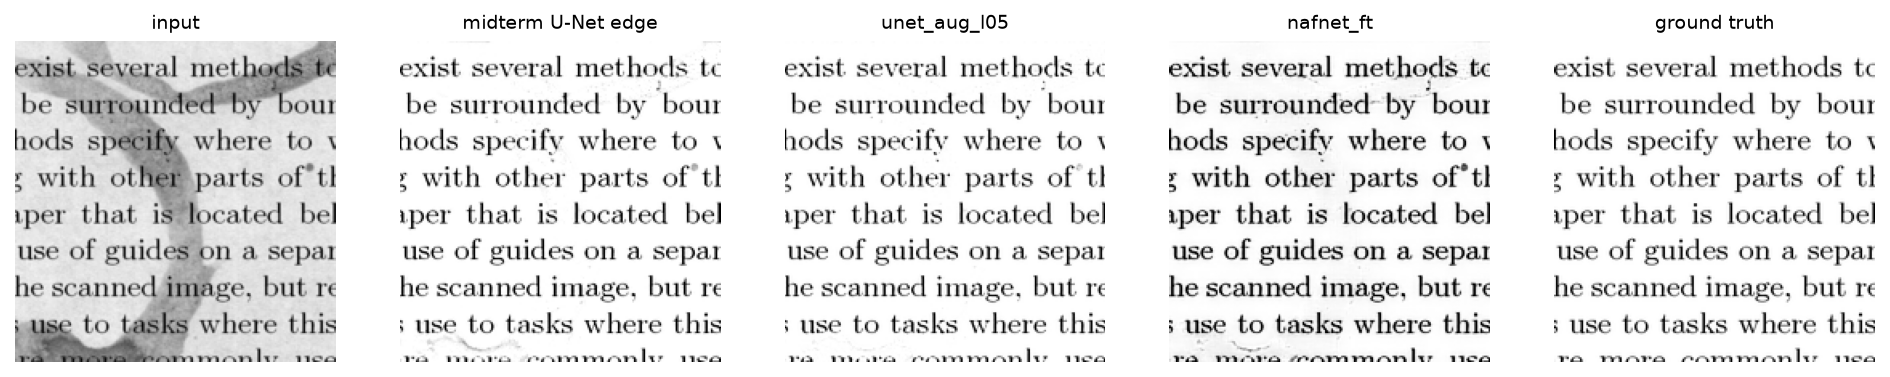

**Augraphy shift: unet_edge_aug คงตัวอักษรได้ดีกว่า midterm ทุกโมเดลยังคงบรรทัดที่บิดไว้ เพราะ denoising ไม่แก้รูปทรง**

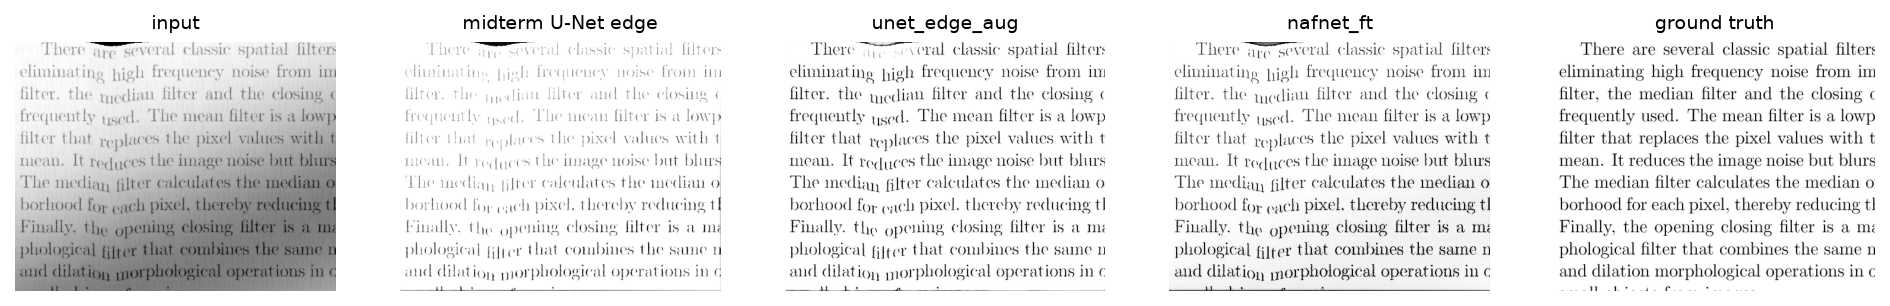

**Augraphy shift (ขยาย): midterm ทำตัวอักษรขาดและจาง**

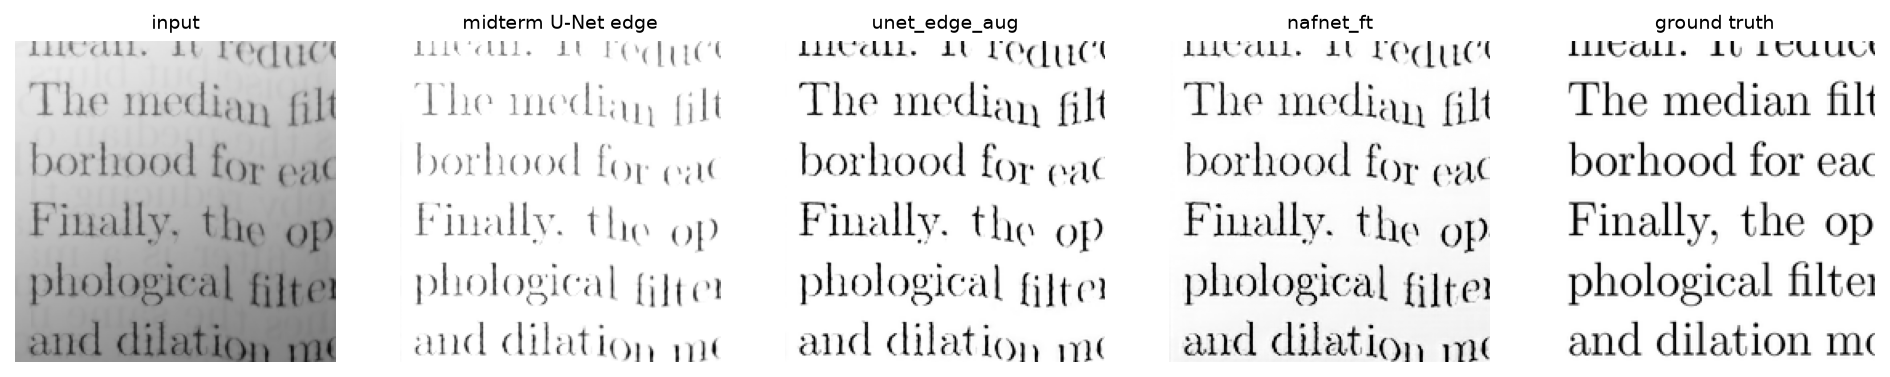

**DIBCO 2017: ไม่ fine-tune หมึกจางหาย, ft_full กู้กลับมาได้, NAFNet FM สูงสุดแต่บางช่วงขาด**

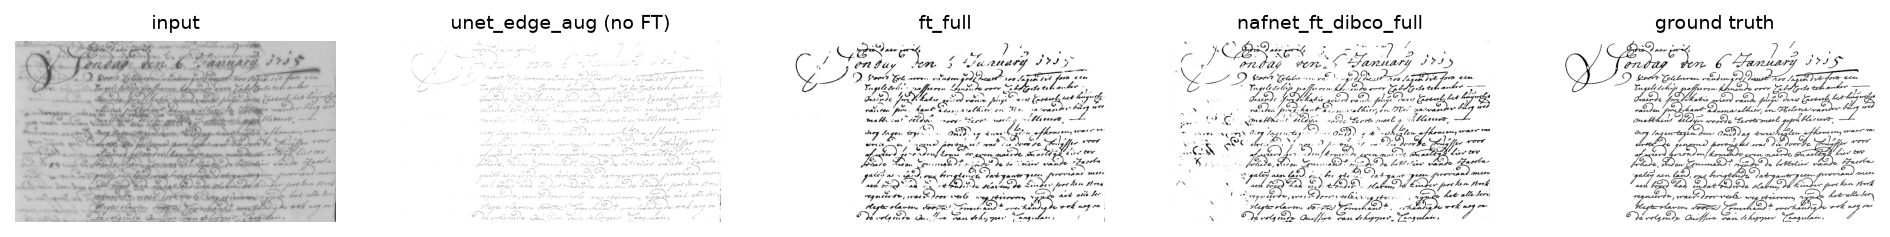

**DIBCO 2017 (ขยาย): ft_full เส้นหนาเป็นก้อน NAFNet เส้นบางใกล้ GT กว่า**

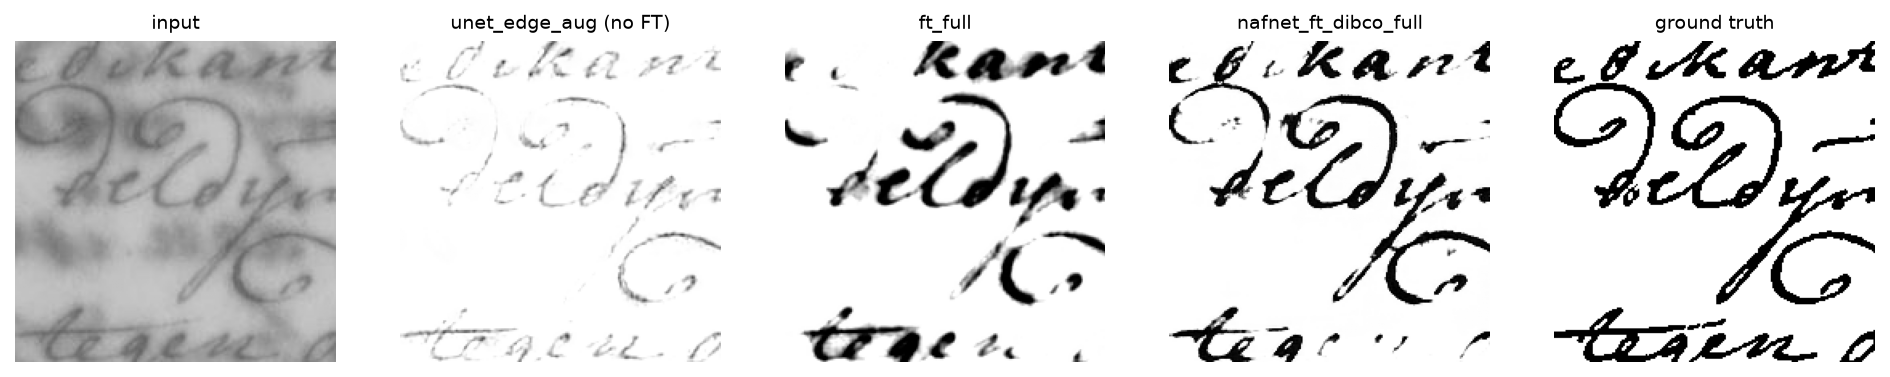

In [13]:
# 13. Figures: data samples, Sobel, U-Net shapes, qualitative grids, zooms, training curves
from IPython.display import Image
_r = subprocess.run([sys.executable, str(MINI / 'tools' / 'make_figures.py'), '--runs', str(RUNS), '--out', str(FIG_DIR)],
                    capture_output=True, text=True)
if _r.returncode:
    print(_r.stdout[-2000:], _r.stderr[-2000:])
print('figures:', len(list(FIG_DIR.glob('*.png'))))
CAPTIONS = [
    ('data_samples', 'ตัวอย่างข้อมูล: Kaggle, Augraphy shift และ DIBCO 2017'),
    ('sobel_explainer', 'Sobel: kernel Gx/Gy และ edge map ที่ใช้ใน edge loss'),
    ('unet_diagram', 'SmallUNet: shape ทุกชั้นจากการรันจริงบนภาพ 256x256'),
    ('curves', 'Validation PSNR ระหว่างเทรน: ซ้าย Kaggle, ขวา fine-tune บน DIBCO'),
    ('qual_kaggle_test', 'Kaggle test: ทุกโมเดลลบคราบได้ใกล้เคียงกัน nafnet_ft ให้ตัวอักษรหนากว่า GT'),
    ('zoom_kaggle_test', 'Kaggle test (ขยาย)'),
    ('qual_augraphy_shift', 'Augraphy shift: unet_edge_aug คงตัวอักษรได้ดีกว่า midterm ทุกโมเดลยังคงบรรทัดที่บิดไว้ เพราะ denoising ไม่แก้รูปทรง'),
    ('zoom_augraphy_shift', 'Augraphy shift (ขยาย): midterm ทำตัวอักษรขาดและจาง'),
    ('qual_dibco2017', 'DIBCO 2017: ไม่ fine-tune หมึกจางหาย, ft_full กู้กลับมาได้, NAFNet FM สูงสุดแต่บางช่วงขาด'),
    ('zoom_dibco2017', 'DIBCO 2017 (ขยาย): ft_full เส้นหนาเป็นก้อน NAFNet เส้นบางใกล้ GT กว่า'),
]
for name, caption in CAPTIONS:
    path = FIG_DIR / f'{name}.png'
    if path.exists():
        display(Markdown(f'**{caption}**'))
        display(Image(filename=str(path)))

### 7.3 Cross-domain benchmark (zero-shot 3 × 3)
ทำเพิ่มตามที่อาจารย์ขอ: เทรนแต่ละโมเดลบน 1 domain (Kaggle, Augraphy หรือ DIBCO) แล้วทดสอบทันทีโดยไม่ fine-tune บน test set ทั้ง 3 ชุด ได้ 6 transfer task (K→A, K→D, A→K, A→D, D→K, D→A) × 5 โมเดล ใช้ recipe และ budget เดียวกับ job บน Kaggle ส่วน KD-CNN ใช้ teacher เป็น SmallUNet ที่เทรนบน domain เดียวกัน

เทรนด้วย `notebooks/cross_domain_colab.ipynb` บน Colab T4 cell นี้อ่านผลประเมินจาก `eval_xd/*.json` สร้างตาราง PSNR, FM, transfer gap และค่าเฉลี่ย 6 task แล้ววาดภาพผลลัพธ์ของ 6 task จาก checkpoint `xd_*`

> **ShallowCNN และ KD-CNN ที่เทรนบน DIBCO collapse:** output เป็นภาพขาวทั้งหน้า (val PSNR คงที่ 10.01 dB, FM = 0) เพราะ ground truth ของ DIBCO เป็นพื้นขาว 94% เราลองลด learning rate และเพิ่ม residual แล้วยังเหมือนเดิม จึงรายงานเป็น finding

# Cross-domain benchmark (zero-shot)
Rows: model trained on Source. Columns: test set. Bold = in-domain. "-" = not evaluated yet.

## PSNR (dB)

| Model | Source | Kaggle test | Augraphy test | DIBCO test |
|---|---|---|---|---|
| SmallUNet (edge+aug) | Kaggle | **31.19** | 17.48 | 12.80 |
| SmallUNet (edge+aug) | Augraphy | 23.43 | **17.67** | 12.98 |
| SmallUNet (edge+aug) | DIBCO | 19.49 | 15.54 | **16.26** |
| DnCNN-lite | Kaggle | **31.94** | 16.72 | 11.80 |
| DnCNN-lite | Augraphy | 19.41 | **17.85** | 12.64 |
| DnCNN-lite | DIBCO | 18.27 | 15.39 | **15.45** |
| ShallowCNN | Kaggle | **28.79** | 16.47 | 12.01 |
| ShallowCNN | Augraphy | 17.99 | **17.47** | 12.77 |
| ShallowCNN | DIBCO | 11.07 | 11.07 | **10.32** |
| KD-CNN | Kaggle | **28.84** | 16.55 | 12.14 |
| KD-CNN | Augraphy | 17.80 | **17.47** | 12.79 |
| KD-CNN | DIBCO | 11.07 | 11.07 | **10.32** |
| NAFNet | Kaggle | **31.19** | 17.16 | 13.02 |
| NAFNet | Augraphy | 24.10 | **17.83** | 12.63 |
| NAFNet | DIBCO | 22.51 | 16.00 | **16.45** |

## FM (%)

| Model | Source | Kaggle test | Augraphy test | DIBCO test |
|---|---|---|---|---|
| SmallUNet (edge+aug) | Kaggle | **88.28** | 78.92 | 61.91 |
| SmallUNet (edge+aug) | Augraphy | 85.10 | **80.02** | 71.37 |
| SmallUNet (edge+aug) | DIBCO | 89.40 | 75.19 | **85.12** |
| DnCNN-lite | Kaggle | **88.13** | 75.96 | 35.97 |
| DnCNN-lite | Augraphy | 79.23 | **79.93** | 68.97 |
| DnCNN-lite | DIBCO | 83.71 | 69.22 | **80.93** |
| ShallowCNN | Kaggle | **88.14** | 73.17 | 41.61 |
| ShallowCNN | Augraphy | 79.23 | **79.98** | 67.69 |
| ShallowCNN | DIBCO | 0.00 | 0.00 | **0.00** |
| KD-CNN | Kaggle | **87.98** | 73.72 | 43.46 |
| KD-CNN | Augraphy | 79.05 | **79.78** | 68.97 |
| KD-CNN | DIBCO | 0.00 | 0.00 | **0.00** |
| NAFNet | Kaggle | **88.88** | 77.63 | 66.53 |
| NAFNet | Augraphy | 84.72 | **80.30** | 68.35 |
| NAFNet | DIBCO | 88.92 | 73.61 | **86.63** |

## Transfer gap, PSNR (dB) (cross-domain minus in-domain on the same test set)

| Model | Source | Kaggle test | Augraphy test | DIBCO test |
|---|---|---|---|---|
| SmallUNet (edge+aug) | Kaggle |  | -0.18 | -3.46 |
| SmallUNet (edge+aug) | Augraphy | -7.77 |  | -3.28 |
| SmallUNet (edge+aug) | DIBCO | -11.70 | -2.13 |  |
| DnCNN-lite | Kaggle |  | -1.13 | -3.65 |
| DnCNN-lite | Augraphy | -12.54 |  | -2.81 |
| DnCNN-lite | DIBCO | -13.67 | -2.45 |  |
| ShallowCNN | Kaggle |  | -1.00 | +1.69 |
| ShallowCNN | Augraphy | -10.80 |  | +2.45 |
| ShallowCNN | DIBCO | -17.72 | -6.40 |  |
| KD-CNN | Kaggle |  | -0.92 | +1.83 |
| KD-CNN | Augraphy | -11.05 |  | +2.47 |
| KD-CNN | DIBCO | -17.77 | -6.40 |  |
| NAFNet | Kaggle |  | -0.67 | -3.43 |
| NAFNet | Augraphy | -7.09 |  | -3.83 |
| NAFNet | DIBCO | -8.68 | -1.83 |  |

## Transfer gap, FM (%) (cross-domain minus in-domain on the same test set)

| Model | Source | Kaggle test | Augraphy test | DIBCO test |
|---|---|---|---|---|
| SmallUNet (edge+aug) | Kaggle |  | -1.10 | -23.22 |
| SmallUNet (edge+aug) | Augraphy | -3.18 |  | -13.75 |
| SmallUNet (edge+aug) | DIBCO | +1.12 | -4.83 |  |
| DnCNN-lite | Kaggle |  | -3.97 | -44.96 |
| DnCNN-lite | Augraphy | -8.89 |  | -11.96 |
| DnCNN-lite | DIBCO | -4.41 | -10.71 |  |
| ShallowCNN | Kaggle |  | -6.81 | +41.61 |
| ShallowCNN | Augraphy | -8.91 |  | +67.69 |
| ShallowCNN | DIBCO | -88.14 | -79.98 |  |
| KD-CNN | Kaggle |  | -6.06 | +43.46 |
| KD-CNN | Augraphy | -8.93 |  | +68.97 |
| KD-CNN | DIBCO | -87.98 | -79.78 |  |
| NAFNet | Kaggle |  | -2.67 | -20.10 |
| NAFNet | Augraphy | -4.16 |  | -18.28 |
| NAFNet | DIBCO | +0.03 | -6.69 |  |

## Mean over the 6 transfer tasks (source != target, zero-shot)

| Rank | Model | Mean PSNR (dB) | Mean FM (%) |
|---|---|---|---|
| 1 | NAFNet | 17.57 | 76.63 |
| 2 | SmallUNet (edge+aug) | 16.95 | 76.98 |
| 3 | DnCNN-lite | 15.71 | 68.85 |
| 4 | KD-CNN | 13.57 | 44.20 |
| 5 | ShallowCNN | 13.56 | 43.62 |


wrote /Users/chayanon/Desktop/Thames/BU/AIE464/mini_project/outputs/final/notebook_figures/cross_domain/xd_qual.png
 


**ผลลัพธ์ของ 6 transfer task (ขยายบริเวณที่มีตัวอักษรมากที่สุด) แถว = source → test set, คอลัมน์ = โมเดล**

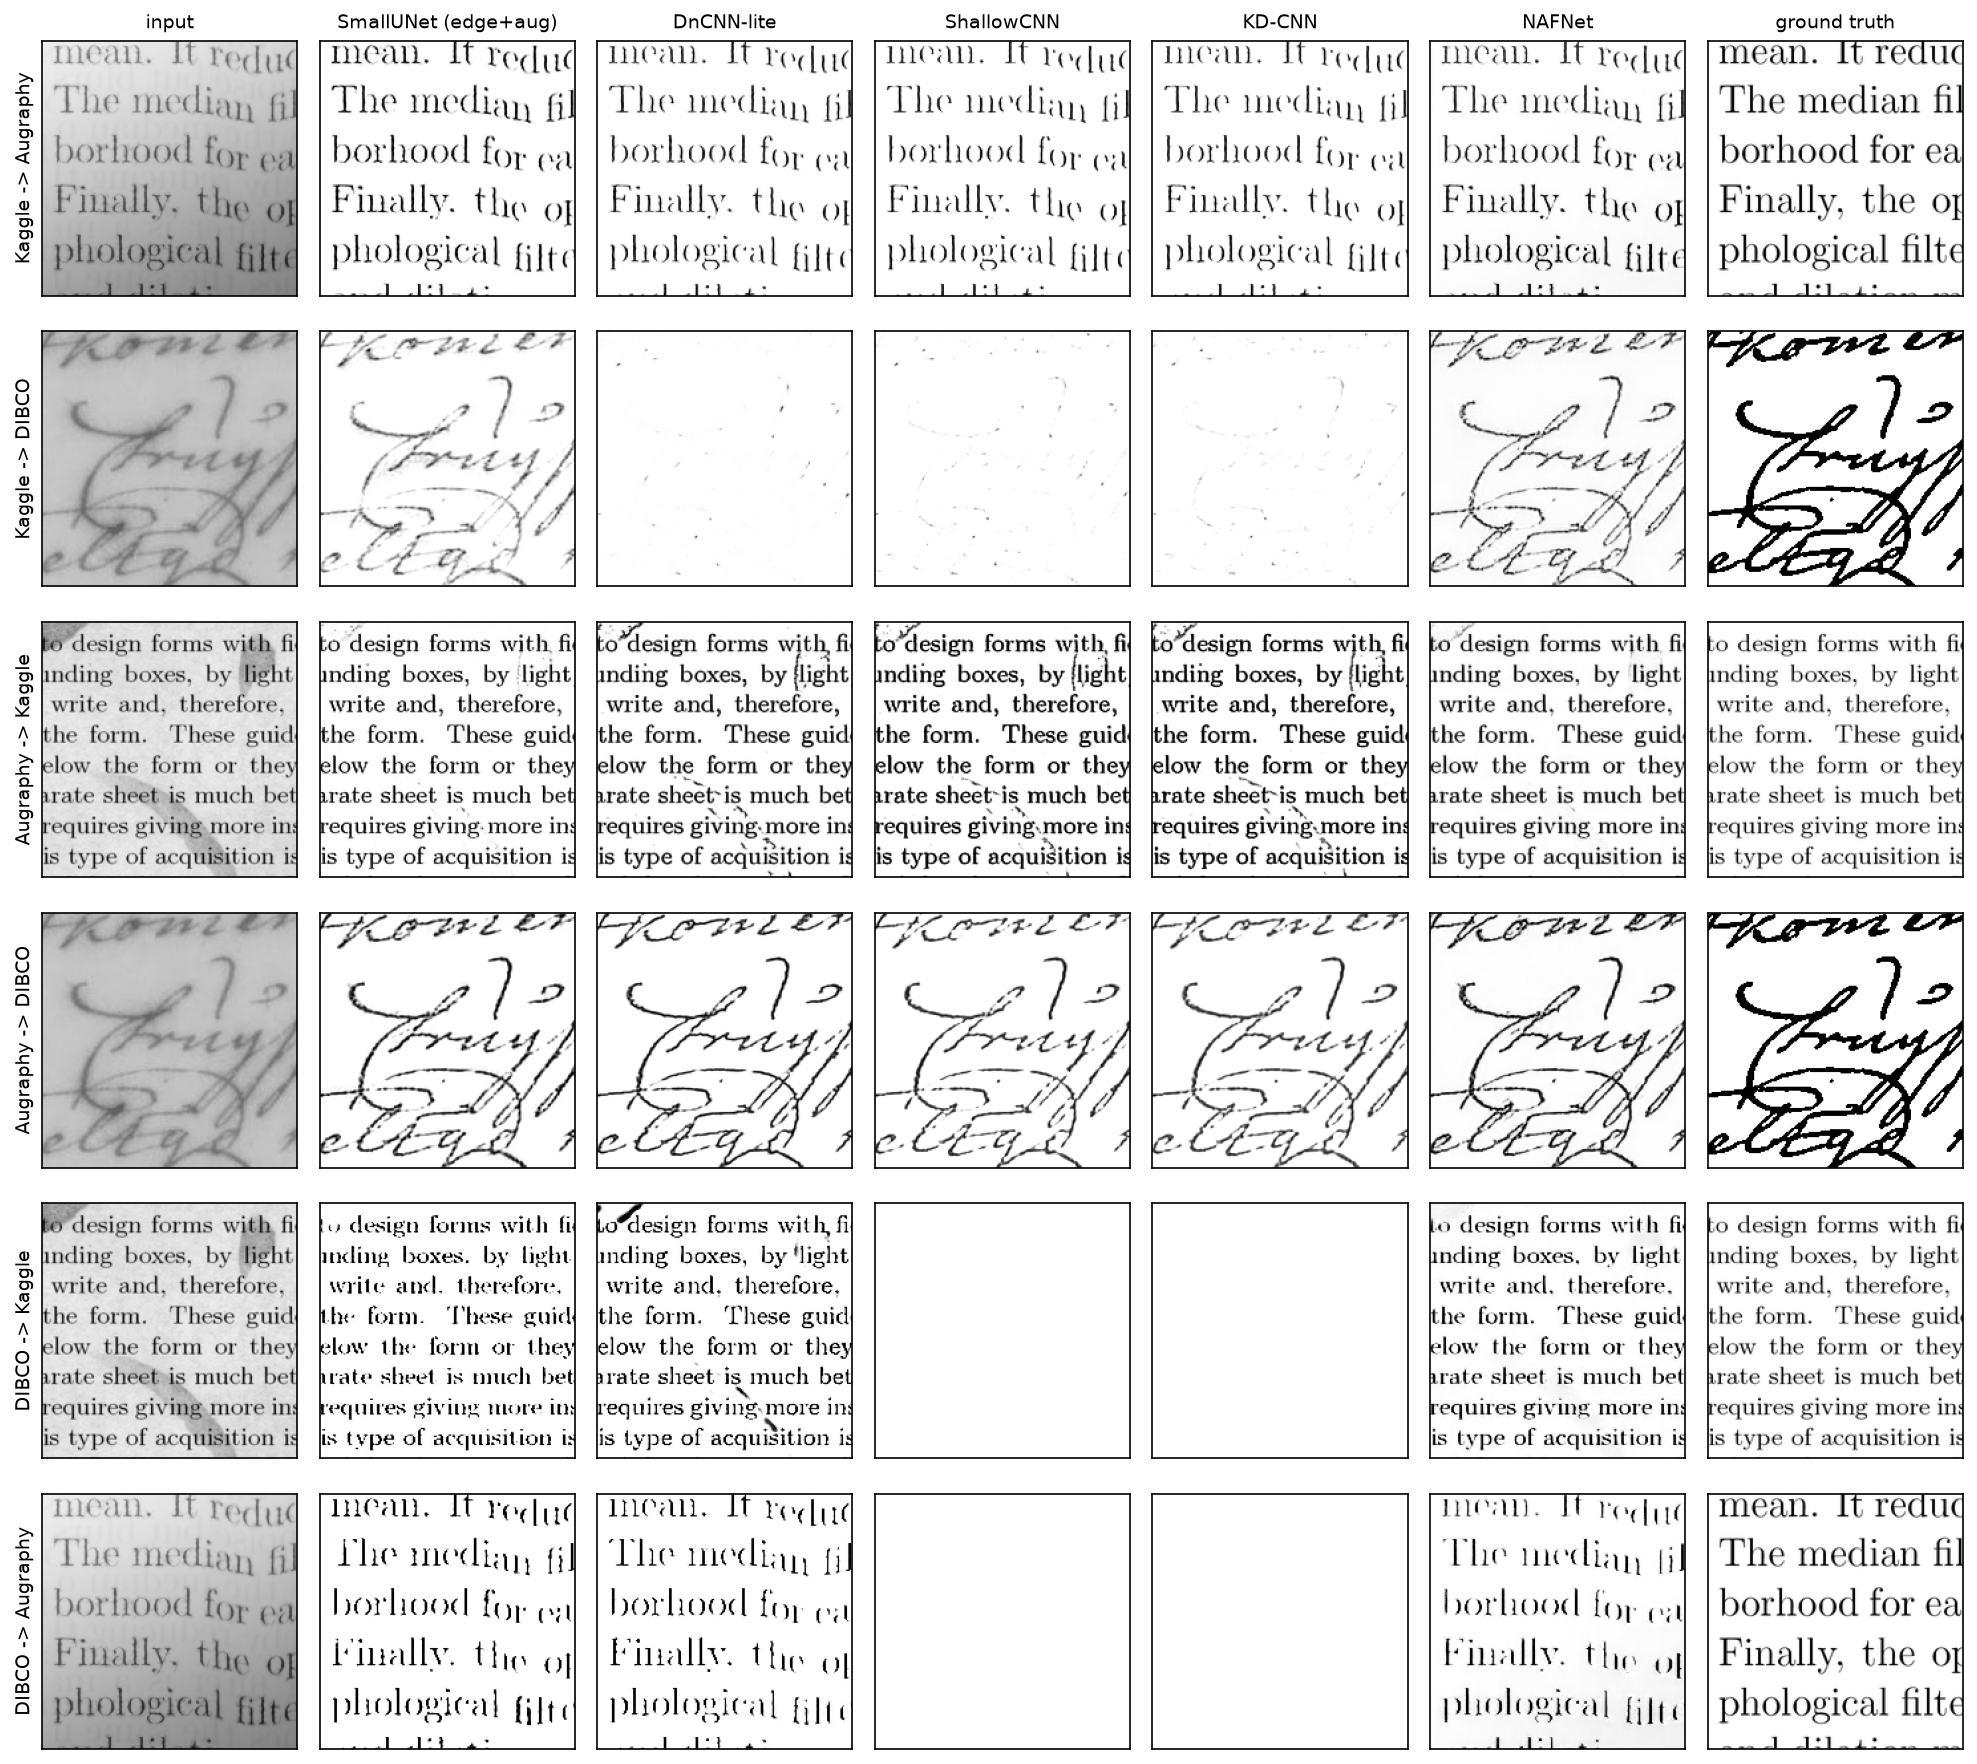

In [14]:
# 14. Cross-domain benchmark: 3x3 tables, mean over the 6 transfer tasks, qualitative grid
from IPython.display import Image, Markdown, display
from src.cross_domain import write_cross_domain_report
EVAL_XD = RUNS / 'eval_xd' if IN_COLAB else MINI / 'results' / 'cross_domain' / 'eval'
XD_MD_PATH = FIG_DIR / 'cross_domain.md'
FIG_DIR.mkdir(parents=True, exist_ok=True)
write_cross_domain_report(EVAL_XD, XD_MD_PATH)
display(Markdown(XD_MD_PATH.read_text()))
_r = subprocess.run([sys.executable, str(MINI / 'tools' / 'make_figures.py'), '--xd-only', '--runs', str(RUNS), '--out', str(FIG_DIR)],
                    capture_output=True, text=True)
print(_r.stdout[-1000:], _r.stderr[-1000:])
xd_fig = FIG_DIR / 'cross_domain' / 'xd_qual.png'
if xd_fig.exists():
    display(Markdown('**ผลลัพธ์ของ 6 transfer task (ขยายบริเวณที่มีตัวอักษรมากที่สุด) แถว = source → test set, คอลัมน์ = โมเดล**'))
    display(Image(filename=str(xd_fig)))

## 8. ข้อสรุปที่มีตัวเลขรองรับ

1. **Augmentation ไม่ได้ทำให้ผล in-domain ดีขึ้นอย่างมีนัยสำคัญ แต่ทำให้ทนต่อ domain shift ได้ชัดเจน**
   - Kaggle: `unet_aug_l05` 32.15 dB เทียบ midterm 31.84 dB (p=0.375) ส่วน `unet_edge_aug` 31.19 dB (p=0.121)
   - Augraphy: `unet_edge_aug` 17.48 dB เทียบ midterm 14.53 dB (median +2.74 dB, p<0.001) text PSNR เพิ่มจาก 5.93 เป็น 10.89 dB และคงที่ทั้ง 3 seeds (17.41–17.48 dB)
2. **ความแปรปรวนจาก seed มีขนาดพอ ๆ กับความต่างระหว่างโมเดลบน Kaggle:** `unet_edge_aug` 3 seeds ได้ 31.19 / 31.37 / 31.64 dB (ช่วง 0.45 dB) ส่วนต่างที่เล็กกว่านี้ เช่นค่า λ จึงยังสรุปไม่ได้
3. **Knowledge Distillation (W10) ได้ผลชัดกับโมเดลเล็ก:** `kd_cnn` 28.84 dB เทียบ midterm CNN 27.71 dB (+1.15 dB median, p<0.001) ขนาดเท่าเดิม 7,265 params และใช้เวลา 4.0 ms
4. **โมเดลที่ไม่ได้ fine-tune ทำงานบน DIBCO แย่กว่า Otsu บนภาพดิบ:** `unet_edge_aug` FM 61.9 เทียบ Otsu 78.0 เพราะโมเดลที่เรียนจาก Kaggle ลบหมึกจาง ๆ ของเอกสารเก่าทิ้ง
5. **Fine-tune (W9) แก้ปัญหานี้ได้:** `ft_full` FM 84.4 จาก 61.9 (+17.1 median, p<0.001) DRD ลดจาก 12.2 เป็น 6.6
6. **LoRA r=8 (W12) ได้ผลเท่า full fine-tune:** FM 84.4 (p=1.0) โดยเทรนเพิ่มแค่ 63k params (ราว 13% ของโมเดล) ส่วน freeze encoder ได้ 77.5 ต่ำสุดในกลุ่ม
7. **NAFNet ดีที่สุดบน DIBCO หลัง fine-tune แต่ไม่คุ้มบน Kaggle:**
   - DIBCO: `nafnet_ft_dibco_full` FM 88.0, DRD 5.05 ดีกว่า `ft_full` (+3.8 FM median, p=0.006)
   - Kaggle: `nafnet_ft` 31.19 dB เท่ากับ U-Net (p=1.0) แต่ params มากกว่า 60 เท่าและช้ากว่า 16 เท่า (141 ms เทียบ 9 ms)
   - Zero-shot ได้แค่ 14.97 dB เพราะเดิมเทรนกับ noise ของกล้อง (SIDD) ไม่ใช่ noise ของเอกสาร
8. **Fine-tune บน DIBCO ทำให้ลืมงานเดิม (catastrophic forgetting):** Kaggle PSNR ตกจาก 31.2 เหลือ 20.0–23.0 dB ทุกวิธี LoRA ไม่ช่วยเพราะ adapter ทำงานตลอด การใช้งานจริงต้องสลับ adapter ตาม domain หรือเทรนร่วมทั้งสอง domain
9. **Cross-domain 6 task: ไม่มี domain ไหนที่เทรนแล้วใช้ได้กับทุก domain:** ช่อง in-domain ดีที่สุดเกือบทุกคอลัมน์ ค่าเฉลี่ย 6 task เรียงตาม PSNR คือ NAFNet 17.57 dB, SmallUNet 16.95, DnCNN-lite 15.71, KD-CNN 13.57 และ ShallowCNN 13.56 ส่วน FM เฉลี่ย SmallUNet สูงกว่า NAFNet เล็กน้อย (76.98 เทียบ 76.63) ทั้งที่ params น้อยกว่า 60 เท่า
10. **Augraphy เป็น source ที่ transfer ไป DIBCO ได้ดีกว่า Kaggle:** FM บน DIBCO 67.7–71.4 เทียบ 36.0–66.5 แต่ยังต่ำกว่าโมเดลที่เทรนบน DIBCO เอง (SmallUNet 85.1, NAFNet 86.6)
11. **โมเดลเล็กมาก collapse บนข้อมูลไม่สมดุล:** ShallowCNN และ KD-CNN ที่เทรนบน DIBCO ตอบภาพขาวทั้งภาพ KD ไม่ช่วยเพราะ student ติดที่จุดเดียวกันก่อนจะได้ประโยชน์จาก teacher

## 9. ข้อจำกัด

- **โค้ดรันได้ไม่เท่ากับโมเดลดี:** pipeline รันครบบน T4 (16 jobs, eval 25 รายการ) แต่ข้อสรุปเรื่องคุณภาพยึดตามตัวเลขในหัวข้อ 7–8 เท่านั้น
- **Seed:** มีหลาย seed เฉพาะ `unet_edge_aug` โมเดลอื่นใช้ seed เดียว การจัดอันดับที่ต่างกันไม่เกินราว 0.5 dB จึงไม่น่าเชื่อถือ
- **ภาพ test ไม่เป็นอิสระต่อกัน:** Kaggle test 24 ภาพมาจาก 6 หน้าต้นฉบับ ค่า p อาจดูดีเกินจริง
- **ขนาด DIBCO:** test มีแค่ 20 ภาพ
- **pFM / DRD:** implement เอง ยังไม่ได้เทียบกับ evaluation tool ทางการของ DIBCO
- **Latency ของ LoRA:** วัดแบบยังไม่ merge น้ำหนักเข้ากับ conv